# User Analysis (Onboarded Users)

This notebook pulls `user_profiles` and `topics` from Firestore once, caches them in `analysis/data/`, then runs:
- skills vs interests match
- interest umbrellas (semantic clustering)
- profile field relationships
- subscribed vs unsubscribed comparisons

Requirements:
- Set `FIREBASE_SERVICE_ACCOUNT_JSON` or `FIREBASE_SERVICE_ACCOUNT_PATH`.
- Optional for semantic embeddings: `pip install sentence-transformers`



In [14]:
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize as sk_normalize

try:
    from sentence_transformers import SentenceTransformer
    _HAS_ST = True
except Exception:
    SentenceTransformer = None
    _HAS_ST = False


def find_repo_root(start: Path) -> Path:
    cur = start.resolve()
    for _ in range(6):
        if (cur / "v1" / "storage.py").exists():
            return cur
        if cur.parent == cur:
            break
        cur = cur.parent
    raise RuntimeError("Could not find repo root with v1/storage.py")


repo_root = find_repo_root(Path.cwd())
if str(repo_root) not in sys.path:
    sys.path.append(str(repo_root))

DATA_DIR = repo_root / "analysis" / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Repo root:", repo_root)
print("Data dir:", DATA_DIR)
print("SentenceTransformers available:", _HAS_ST)



Repo root: /Users/ttomar/Documents/personal/claudia
Data dir: /Users/ttomar/Documents/personal/claudia/analysis/data
SentenceTransformers available: True


In [25]:
if "repo_root" not in globals():
    def _find_repo_root(start: Path) -> Path:
        cur = start.resolve()
        for _ in range(6):
            if (cur / "v1" / "storage.py").exists():
                return cur
            if cur.parent == cur:
                break
            cur = cur.parent
        raise RuntimeError("Could not find repo root with v1/storage.py")

    repo_root = _find_repo_root(Path.cwd())
    if str(repo_root) not in sys.path:
        sys.path.append(str(repo_root))

from v1.storage import FirestoreStore

service_account_file = repo_root / "anybrew-7c6c1-firebase-adminsdk-fbsvc-fe164fd73a.json"
if service_account_file.exists():
    os.environ["FIREBASE_SERVICE_ACCOUNT_PATH"] = str(service_account_file)


import firebase_admin


def _reset_firebase_apps():
    for app in list(firebase_admin._apps.values()):
        firebase_admin.delete_app(app)


def _serialize(obj):
    if obj is None:
        return None
    if hasattr(obj, "isoformat"):
        return obj.isoformat()
    if isinstance(obj, dict):
        return {k: _serialize(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [_serialize(v) for v in obj]
    return obj


profiles_path = DATA_DIR / "user_profiles.json"
topics_path = DATA_DIR / "topics.json"


def fetch_and_cache():
    _reset_firebase_apps()
    store = FirestoreStore()
    profiles = []
    for doc in store.db.collection("user_profiles").stream():
        data = doc.to_dict() or {}
        profiles.append({"uid": doc.id, **_serialize(data)})

    topics = []
    for doc in store.db.collection("topics").stream():
        data = doc.to_dict() or {}
        topics.append({"topic_id": doc.id, **_serialize(data)})

    profiles_path.write_text(json.dumps(profiles, ensure_ascii=True, indent=2))
    topics_path.write_text(json.dumps(topics, ensure_ascii=True, indent=2))
    return profiles, topics


if profiles_path.exists() and topics_path.exists():
    profiles = json.loads(profiles_path.read_text())
    topics = json.loads(topics_path.read_text())
else:
    profiles, topics = fetch_and_cache()

print("Profiles:", len(profiles))
print("Topics:", len(topics))



Profiles: 166
Topics: 219


In [26]:
def _listify(value):
    if not value:
        return []
    if isinstance(value, list):
        return [v for v in value if isinstance(v, str) and v.strip()]
    if isinstance(value, str):
        return [value]
    return []


def _norm_term(value: str) -> str:
    return (value or "").strip().lower()


def _norm_terms(values):
    return list({
        _norm_term(v) for v in values
        if isinstance(v, str) and v.strip()
    })


rows = []
for p in profiles:
    if p.get("onboarded") is not True:
        continue
    row = {
        "uid": p.get("uid") or p.get("id") or p.get("user_id"),
        "subscriptionStatus": p.get("subscriptionStatus", "none"),
        "subscribed": p.get("subscriptionStatus") in ["trial", "active"],
        "role": p.get("role", ""),
        "learningStyle": p.get("learningStyle", ""),
        "contentDepth": p.get("contentDepth", ""),
        "goalsShortTerm": (p.get("goals") or {}).get("shortTerm", ""),
        "goalsLongTerm": (p.get("goals") or {}).get("longTerm", ""),
        "interests": _norm_terms(_listify(p.get("interests"))),
        "hobbies": _norm_terms(_listify(p.get("hobbies"))),
        "skills": _norm_terms(_listify(p.get("skills"))),
    }
    rows.append(row)

df = pd.DataFrame(rows)
if df.empty:
    raise RuntimeError("No onboarded users found.")

df["interest_terms"] = df["interests"] + df["hobbies"]
df["skills_terms"] = df["skills"]

df.head()



,uid,subscriptionStatus,subscribed,role,learningStyle,contentDepth,goalsShortTerm,goalsLongTerm,interests,hobbies,skills,interest_terms,skills_terms
0,0mZoL8hUxDeeENPc2pVhyXg5xaJ2,none,False,Software Engineer,,NaN,,,"[ai, world news]",[],[all],"[ai, world news]",[all]
1,0oeCnK4OPIZOzoVFYpjJvlCBONM2,none,False,Software Engineer,,NaN,Build company,,"[spiritual, technology, sports, finance]","[cricket, running]",[c#],"[spiritual, technology, sports, finance, crick...",[c#]
2,149Hx625R7dzQY9om3gbALEyIIv1,none,False,Designer,,surprise,Build an Online Brand,,"[ux research, productivity, gaming, ux design]","[pottery, cycling]",[ux-designer],"[ux research, productivity, gaming, ux design,...",[ux-designer]
3,1iUj0ZrVZibPgFi5CJzFSziT1mC2,active,True,Product Manager,,NaN,,,"[management, art, product design, vibe coding]",[],"[ai studio, cursor]","[management, art, product design, vibe coding]","[ai studio, cursor]"
4,210qZ9XJNta5d3xfZXGfVRmbZWk1,none,False,Software Engineer,,surprise,,,"[golang, ai, system design, performance, ai ml...","[manhua, anime, manhwa]",[expert],"[golang, ai, system design, performance, ai ml...",[expert]


In [27]:
_EMBED_MODEL = None


def embed_terms(terms):
    global _EMBED_MODEL
    if not terms:
        return np.zeros((0, 1))
    if _HAS_ST:
        if _EMBED_MODEL is None:
            _EMBED_MODEL = SentenceTransformer("all-MiniLM-L6-v2")
        emb = _EMBED_MODEL.encode(terms, normalize_embeddings=True)
        return np.array(emb)
    vec = TfidfVectorizer()
    tfidf = vec.fit_transform(terms)
    emb = sk_normalize(tfidf)
    return emb.toarray()


from sklearn.cluster import AgglomerativeClustering

CLUSTER_METHOD = "agglomerative"  # "agglomerative" or "kmeans"
CLUSTER_K = None  # set an int to force a fixed k
AGGLO_DISTANCE = 0.65  # lower = tighter clusters
LABEL_TOP_N = 2

all_interest_terms = sorted({t for terms in df["interest_terms"] for t in terms})
print("Unique interest/hobby terms:", len(all_interest_terms))

if len(all_interest_terms) >= 3:
    embeddings = embed_terms(all_interest_terms)
    if CLUSTER_METHOD == "kmeans":
        if CLUSTER_K is None:
            max_k = min(12, len(all_interest_terms) - 1)
            min_k = 3 if len(all_interest_terms) >= 6 else 2

            best_k = min_k
            best_score = -1
            for k in range(min_k, max_k + 1):
                try:
                    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
                    labels = kmeans.fit_predict(embeddings)
                    if len(set(labels)) < 2:
                        continue
                    score = silhouette_score(embeddings, labels)
                    if score > best_score:
                        best_k, best_score = k, score
                except Exception:
                    continue
        else:
            best_k = CLUSTER_K
            best_score = None

        kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
        labels = kmeans.fit_predict(embeddings)
        print("Chosen clusters:", best_k, "| silhouette:", round(best_score, 3) if best_score is not None else "fixed")
    else:
        if CLUSTER_K is None:
            clusterer = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=AGGLO_DISTANCE,
                metric="cosine",
                linkage="average",
            )
        else:
            clusterer = AgglomerativeClustering(
                n_clusters=CLUSTER_K,
                metric="cosine",
                linkage="average",
            )
        labels = clusterer.fit_predict(embeddings)
        print("Agglomerative clusters:", len(set(labels)))
else:
    embeddings = np.zeros((len(all_interest_terms), 1))
    labels = np.zeros(len(all_interest_terms), dtype=int)
    print("Too few terms for clustering; using single cluster")

term_embeddings = {t: e for t, e in zip(all_interest_terms, embeddings)}

term_freq = {}
for terms in df["interest_terms"]:
    for t in terms:
        term_freq[t] = term_freq.get(t, 0) + 1

cluster_to_terms = {}
for term, lab in zip(all_interest_terms, labels):
    cluster_to_terms.setdefault(int(lab), []).append(term)


def _cosine(a, b):
    denom = (np.linalg.norm(a) * np.linalg.norm(b)) + 1e-9
    return float(np.dot(a, b) / denom)


def build_umbrella_name(cluster_terms):
    if not cluster_terms:
        return "misc"
    embs = [term_embeddings[t] for t in cluster_terms if t in term_embeddings]
    if not embs:
        ranked = sorted(cluster_terms, key=lambda t: term_freq.get(t, 0), reverse=True)
        return " / ".join(ranked[:LABEL_TOP_N])
    centroid = np.mean(np.vstack(embs), axis=0)
    ranked = sorted(
        cluster_terms,
        key=lambda t: _cosine(term_embeddings.get(t), centroid),
        reverse=True,
    )
    return " / ".join(ranked[:LABEL_TOP_N])


MANUAL_UMBRELLA_NAMES = {
    # 0: "ai / ml",
}

umbrella_map = {}
cluster_summary = []
for cid, terms in cluster_to_terms.items():
    name = MANUAL_UMBRELLA_NAMES.get(cid) or build_umbrella_name(terms)
    ranked_by_freq = sorted(terms, key=lambda t: term_freq.get(t, 0), reverse=True)[:8]
    ranked_by_centroid = sorted(
        terms,
        key=lambda t: _cosine(term_embeddings.get(t), np.mean(np.vstack([term_embeddings[x] for x in terms]), axis=0)),
        reverse=True,
    )[:8]
    cluster_summary.append({
        "cluster": cid,
        "size": len(terms),
        "label": name,
        "top_terms": ranked_by_centroid,
        "top_freq": ranked_by_freq,
    })
    for t in terms:
        umbrella_map[t] = name

cluster_summary_df = pd.DataFrame(cluster_summary).sort_values("size", ascending=False)
cluster_summary_df.head(20)


df["umbrella_terms"] = df["interest_terms"].apply(
    lambda terms: sorted({umbrella_map.get(t, "misc") for t in terms})
)

umbrella_counts = {}
for umbrellas in df["umbrella_terms"]:
    for u in umbrellas:
        umbrella_counts[u] = umbrella_counts.get(u, 0) + 1

umbrella_counts_df = (
    pd.DataFrame([{"umbrella": k, "users": v} for k, v in umbrella_counts.items()])
    .sort_values("users", ascending=False)
)

umbrella_counts_df.head(20)



Unique interest/hobby terms: 431


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1736.53it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Agglomerative clusters: 119


,umbrella,users
0,ai agents / ai,60
11,software design / design,41
3,fitness / working out,27
15,product management / product strategy,27
53,saas startups / startup marketing,23
44,music / music production,23
13,creativity / art,22
25,science / studying,20
10,productivity / productivity ideas,20
4,new tech / latest tech,20


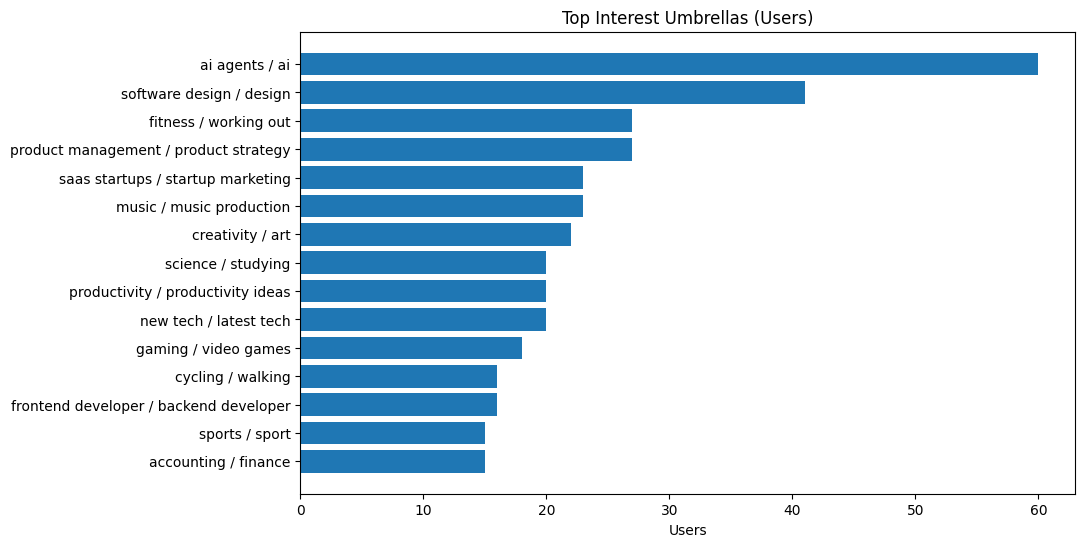

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plot_df = umbrella_counts_df.head(15)
plt.barh(plot_df["umbrella"], plot_df["users"])
plt.gca().invert_yaxis()
plt.title("Top Interest Umbrellas (Users)")
plt.xlabel("Users")
plt.show()



In [29]:
all_skill_terms = sorted({t for terms in df["skills_terms"] for t in terms})
all_terms = sorted(set(all_interest_terms) | set(all_skill_terms))

term_embeddings = {}
if all_terms:
    all_emb = embed_terms(all_terms)
    for term, emb in zip(all_terms, all_emb):
        term_embeddings[term] = emb


def cosine(a, b):
    if a is None or b is None:
        return np.nan
    denom = (np.linalg.norm(a) * np.linalg.norm(b)) + 1e-9
    return float(np.dot(a, b) / denom)


def skill_interest_match(skills, interests):
    if not skills or not interests:
        return np.nan
    s_embs = [term_embeddings.get(s) for s in skills if s in term_embeddings]
    i_embs = [term_embeddings.get(i) for i in interests if i in term_embeddings]
    if not s_embs or not i_embs:
        return np.nan
    scores = []
    for s in s_embs:
        best = max(cosine(s, i) for i in i_embs)
        scores.append(best)
    return float(np.mean(scores)) if scores else np.nan


df["skill_interest_match"] = df.apply(
    lambda r: skill_interest_match(r["skills_terms"], r["interest_terms"]),
    axis=1,
)

df["skill_interest_match"].describe()



count    119.000000
mean       0.482076
std        0.211469
min        0.075818
25%        0.330657
50%        0.431661
75%        0.599599
max        1.000000
Name: skill_interest_match, dtype: float64

<Figure size 600x400 with 0 Axes>

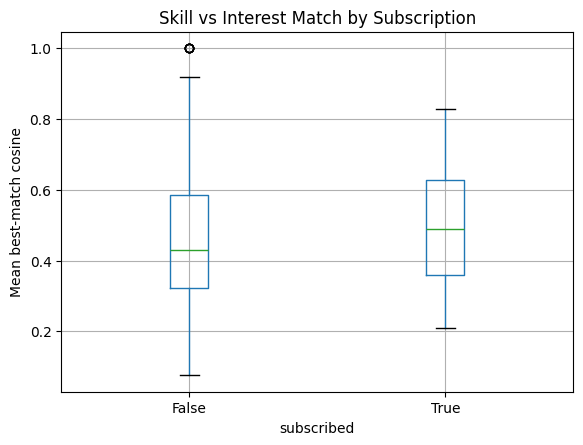

Low-match users: 24


In [30]:
plt.figure(figsize=(6, 4))
df.boxplot(column="skill_interest_match", by="subscribed")
plt.title("Skill vs Interest Match by Subscription")
plt.suptitle("")
plt.ylabel("Mean best-match cosine")
plt.show()

low_threshold = 0.3
low_match = df[df["skill_interest_match"] < low_threshold]
print("Low-match users:", len(low_match))



In [31]:
def explode_umbrella(frame: pd.DataFrame) -> pd.DataFrame:
    return frame.explode("umbrella_terms")

role_umbrella = (
    explode_umbrella(df)
    .groupby(["role", "umbrella_terms"])
    .size()
    .reset_index(name="users")
    .sort_values("users", ascending=False)
)

learning_umbrella = (
    explode_umbrella(df)
    .groupby(["learningStyle", "umbrella_terms"])
    .size()
    .reset_index(name="users")
    .sort_values("users", ascending=False)
)

content_umbrella = (
    explode_umbrella(df)
    .groupby(["contentDepth", "umbrella_terms"])
    .size()
    .reset_index(name="users")
    .sort_values("users", ascending=False)
)

role_umbrella.head(15)



,role,umbrella_terms,users
218,Software Engineer,ai agents / ai,23
277,Software Engineer,software design / design,17
70,Founder,ai agents / ai,11
241,Software Engineer,frontend developer / backend developer,11
275,Software Engineer,saas startups / startup marketing,10
239,Software Engineer,fitness / working out,10
260,Software Engineer,new tech / latest tech,9
265,Software Engineer,performance / frontend-performance,8
270,Software Engineer,productivity / productivity ideas,8
61,Designer,software design / design,8


In [32]:
summary = df.groupby("subscribed").agg(
    users=("uid", "count"),
    avg_interests=("interest_terms", lambda x: np.mean([len(v) for v in x])),
    avg_skills=("skills_terms", lambda x: np.mean([len(v) for v in x])),
    avg_match=("skill_interest_match", "mean"),
)

summary



,users,avg_interests,avg_skills,avg_match
subscribed,,,,
False,105,6.714286,2.990476,0.480048
True,15,8.733333,3.266667,0.496140


In [33]:
def top_umbrellas_by_group(frame: pd.DataFrame, group_col: str, top_n: int = 10) -> pd.DataFrame:
    rows = []
    for group, gdf in frame.groupby(group_col):
        counts = {}
        for umbrellas in gdf["umbrella_terms"]:
            for u in umbrellas:
                counts[u] = counts.get(u, 0) + 1
        top = sorted(counts.items(), key=lambda kv: kv[1], reverse=True)[:top_n]
        rows.append({"group": group, "top_umbrellas": top})
    return pd.DataFrame(rows)


top_umbrellas_by_group(df, "subscribed")



,group,top_umbrellas
0,False,"[(ai agents / ai, 54), (software design / desi..."
1,True,"[(software design / design, 6), (ai agents / a..."


In [34]:
umbrella_map_path = DATA_DIR / "umbrella_map.json"
umbrella_counts_path = DATA_DIR / "umbrella_counts.csv"
user_summary_path = DATA_DIR / "user_summary.csv"

umbrella_map_path.write_text(json.dumps(umbrella_map, ensure_ascii=True, indent=2))
umbrella_counts_df.to_csv(umbrella_counts_path, index=False)

df[[
    "uid",
    "subscribed",
    "interest_terms",
    "skills_terms",
    "skill_interest_match",
    "umbrella_terms",
]].to_csv(user_summary_path, index=False)

print("Saved:", umbrella_map_path)
print("Saved:", umbrella_counts_path)
print("Saved:", user_summary_path)



Saved: /Users/ttomar/Documents/personal/claudia/analysis/data/umbrella_map.json
Saved: /Users/ttomar/Documents/personal/claudia/analysis/data/umbrella_counts.csv
Saved: /Users/ttomar/Documents/personal/claudia/analysis/data/user_summary.csv
